# Лабораторная работа №6: Построение и оценка VLM-пайплайна

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.


## Цели обучения

После работы студент должен уметь:

- Запустить quantized VLM 2–4B.
- Создать evaluation JSONL.
- Сравнить prompts, resolution и decoding; разметить ошибки.


## Теоретическая часть

VLM связывает visual encoder, projector и language model. Оценка должна разделять captioning, VQA, OCR и structured extraction, фиксировать prompt, decoding и ошибки: hallucination, counting, spatial relations.

![Пример изображения для Visual Question Answering](https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/transformers/tasks/vqa-example.png)


### Математическая постановка

Для открытых ответов одной exact match недостаточно. Используют нормализованный EM/F1, judge rubric и ручную разметку ошибок. Hallucination rate: $H=N_{unsupported}/N_{claims}$.


### Материалы

- [Transformers multimodal chat templates](https://huggingface.co/docs/transformers/chat_templating_multimodal)
- [VLMEvalKit](https://github.com/open-compass/VLMEvalKit)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Практическое задание

1. Запустить quantized VLM 2–4B.
2. Создать evaluation JSONL.
3. Сравнить prompts, resolution и decoding; разметить ошибки.

**Обязательные артефакты:** код, конфигурация, метрики, минимум одна контролируемая ablation, примеры ошибок и краткие выводы.


### Профиль вычислений

- **Основной режим:** VLM 4B NF4 inference, одно изображение.
- **Ограничение данных:** 20 evaluation examples: 5 на каждый из четырёх типов задач.
- **Fallback:** VLM 2B NF4 с тем же API.
- Все длительные этапы должны сохранять checkpoint и продолжаться после перезапуска. Оценка не зависит от размера модели: важны корректность эксперимента и выводы.


**Оценивание.** Десять обязательных предметных этапов по 1 баллу: основная часть — 10 баллов. Творческий бонус — отдельно 1 балл, не заменяет обязательные этапы. Полный режим оценивается по реальным данным и инференсу; `FAST_DEV_RUN=True` служит только smoke-проверкой, его показатели не являются отчётными.


## Реализация


In [4]:
# Базовое воспроизводимое окружение
from pathlib import Path
import json, os, random, time
import numpy as np

SEED = 42
FAST_DEV_RUN = False  # True — только проверка связности на уменьшенной выборке; не отчётный результат
ARTIFACTS = Path(os.getenv("CV_ARTIFACTS", "artifacts"))
ARTIFACTS.mkdir(exist_ok=True)
random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    torch.manual_seed(SEED)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
except ImportError:
    torch = None
    DEVICE = "cpu"
# Датасеты курса лежат в общем каталоге <корень курса>/data:
# notebook выполняется из labs/lab_XX_*/, поэтому корень курса — cwd.parent.parent.
# Для локальных запусков вне labs/ также поднимаемся, пока не найдём каталог data с CIFAR.
_CANDIDATES = [Path.cwd().parent.parent / "data", Path.cwd().parent / "data", Path.cwd() / "data"]
DATA_ROOT = Path(os.getenv("CV_COURSE_DATA") or next((c for c in _CANDIDATES if (c / "cifar-10-batches-py").exists()), _CANDIDATES[0]))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
print({"device": DEVICE, "fast_dev_run": FAST_DEV_RUN, "data_root": str(DATA_ROOT)})


{'device': 'cuda', 'fast_dev_run': False, 'data_root': 'c:\\Users\\Lenovo\\Projects\\data'}


In [5]:
def check(condition, message):
    """Мини-проверка в стиле YAAM: молчит, если всё хорошо; печатает, если найдена проблема."""
    if condition:
        print(f"✔ {message}")
    else:
        print(f"✘ ВНИМАНИЕ: {message}")

### Оценочный набор с происхождением

*Вес: 1 балл.*

**Постановка.** Используйте PixMo-Cap, PixMo-AskModelAnything, PixMo-Docs и PixMo-Count с опубликованными эталонами и сохраняйте происхождение каждой записи; локальных файлов от студента не требуется.

Выполните следующие действия:
1. Загрузите открытые изображения и опубликованные ответы через `open_eval_data.load_open_eval`; сохраните URL, split, индекс записи и сведения о лицензировании.
2. Проверьте размер набора и наличие captioning, VQA, OCR и structured extraction.

**Результат.** eval.jsonl с проверяемыми примерами и абсолютными либо существующими путями.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


Загружено с HuggingFace Datasets Server: 20 примеров
✔ размер набора 20/20
✔ категория caption: 5
✔ категория open_vqa: 5
✔ категория document_qa: 5
✔ категория object_count_json: 5
✔ все изображения существуют локально
✔ происхождение заполнено (source, split, license)


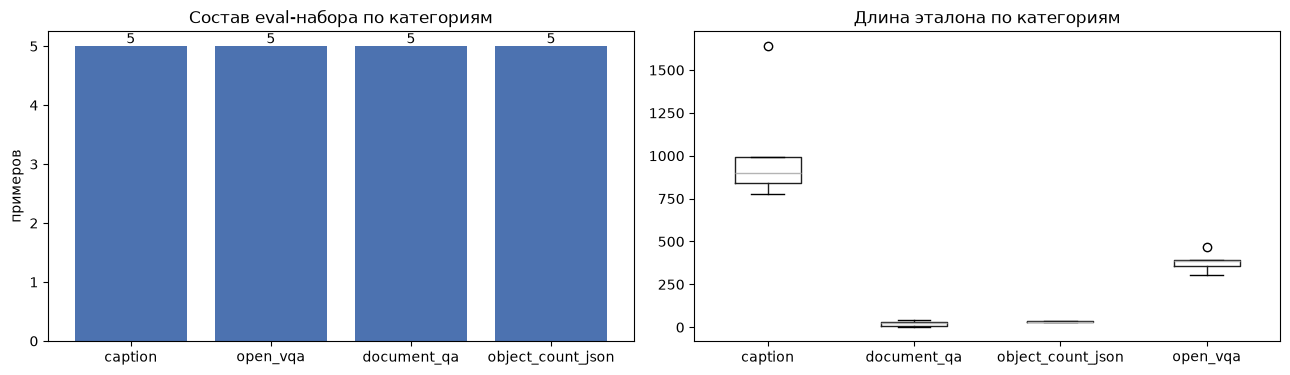


✔ eval.jsonl: C:\Users\Lenovo\Projects\PythonSOTA\lab6\artifacts\eval.jsonl (20 записей)

Примеры (по одному на категорию):


,category,question,reference
0,caption,Describe the image.,"This photograph depicts a striking black bird,..."
1,open_vqa,What type of machine is this?,This is a vintage-style popcorn cart. It featu...
2,document_qa,What is the total estimated cost?,"$2,500"
3,object_count_json,How many wild birds are visible? Return only J...,"{""label"": ""wild birds"", ""count"": 10}"


In [6]:
# Загружаем PixMo через open_eval_data с кэшем в artifacts/data
# Показываем состав набора: bar chart + таблица примеров
import matplotlib.pyplot as plt
import pandas as pd

eval_path = ARTIFACTS / "eval.jsonl"

if eval_path.exists():
    examples = [json.loads(l) for l in eval_path.read_text(encoding="utf-8").splitlines() if l.strip()]
    if FAST_DEV_RUN and len(examples) > 4:
        seen, subset = set(), []
        for ex in examples:
            if ex["category"] not in seen:
                seen.add(ex["category"]); subset.append(ex)
        examples = subset
    print(f"Кэш найден: {len(examples)} примеров из eval.jsonl")
else:
    from open_eval_data import load_open_eval
    examples = load_open_eval(root=str(ARTIFACTS / "data"), per_task=1 if FAST_DEV_RUN else None)
    with eval_path.open("w", encoding="utf-8") as f:
        for ex in examples:
            f.write(json.dumps(ex, ensure_ascii=False) + "\n")
    print(f"Загружено с HuggingFace Datasets Server: {len(examples)} примеров")

cats = {}
for ex in examples:
    cats[ex["category"]] = cats.get(ex["category"], 0) + 1

expected = 4 if FAST_DEV_RUN else 20
check(len(examples) == expected, f"размер набора {len(examples)}/{expected}")
for c in ("caption", "open_vqa", "document_qa", "object_count_json"):
    check(c in cats, f"категория {c}: {cats.get(c, 0)}")
check(all(Path(ex["image"]).is_file() for ex in examples), "все изображения существуют локально")
check(all(ex.get("source") and ex.get("source_split") and ex.get("license") for ex in examples),
      "происхождение заполнено (source, split, license)")

# ---------- ВИЗУАЛ 1: состав набора ----------
df_eval = pd.DataFrame(examples)
df_eval["ref_len"] = df_eval["reference"].astype(str).str.len()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cnt = df_eval["category"].value_counts()
axes[0].bar(cnt.index, cnt.values, color="#4C72B0")
axes[0].set_title("Состав eval-набора по категориям")
axes[0].set_ylabel("примеров")
for i, v in enumerate(cnt.values):
    axes[0].text(i, v + 0.05, str(v), ha="center")

df_eval.boxplot(column="ref_len", by="category", ax=axes[1], grid=False)
axes[1].set_title("Длина эталона по категориям"); axes[1].set_xlabel("")
plt.suptitle(""); plt.tight_layout()
plt.savefig(ARTIFACTS / "eval_distribution.png", dpi=110); plt.show()

print(f"\n✔ eval.jsonl: {eval_path.resolve()} ({len(examples)} записей)")
print("\nПримеры (по одному на категорию):")
display(df_eval.groupby("category").head(1)[["category","question","reference"]].reset_index(drop=True))

### Модель и режим квантования

*Вес: 1 балл.*

**Постановка.** Фиксация версии модели и precision нужна для интерпретации результатов инференса.

Выполните следующие действия:
1. Загрузите processor и VLM.
2. На GPU включите NF4; без GPU не запускайте полный режим.

**Результат.** Объекты processor, model и model_id.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [7]:
# SmolVLM2-2.2B в NF4 — ~1.45 ГБ весов, комфортно на 4 ГБ VRAM
# Processor + model + фиксация версий → model_info.json
import transformers
from transformers import AutoProcessor, BitsAndBytesConfig

try:
    from transformers import AutoModelForImageTextToText as AutoVLM
except ImportError:
    from transformers import AutoModelForVision2Seq as AutoVLM

MODEL_ID = "HuggingFaceTB/SmolVLM2-2.2B-Instruct"
if DEVICE != "cuda" and not FAST_DEV_RUN:
    raise RuntimeError("Полный режим требует CUDA. FAST_DEV_RUN=True — только smoke-проверка.")

processor = AutoProcessor.from_pretrained(MODEL_ID)

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16,
    bnb_4bit_use_double_quant=True,
)
model = AutoVLM.from_pretrained(
    MODEL_ID,
    quantization_config=bnb,
    device_map="auto",
    low_cpu_mem_usage=True,
)
model.eval()

info = {
    "model_id": MODEL_ID, "precision": "nf4", "device": DEVICE,
    "transformers": transformers.__version__, "torch": torch.__version__,
}
(ARTIFACTS / "model_info.json").write_text(json.dumps(info, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(info, ensure_ascii=False, indent=2))

if DEVICE == "cuda":
    mem = torch.cuda.memory_allocated() / 2**30
    print(f"\nПамять CUDA под модель: {mem:.2f} GiB")
    check(mem < 3.0, f"модель занимает {mem:.2f} ГБ VRAM (< 3 ГБ — есть запас)")

W1027 19:13:19.412000 18636 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
W1027 19:13:26.541000 18636 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


Loading weights:   0%|          | 0/657 [00:00<?, ?it/s]

{
  "model_id": "HuggingFaceTB/SmolVLM2-2.2B-Instruct",
  "precision": "nf4",
  "device": "cuda",
  "transformers": "5.21.0.dev0",
  "torch": "2.11.0+cu128"
}

Память CUDA под модель: 1.74 GiB
✔ модель занимает 1.74 ГБ VRAM (< 3 ГБ — есть запас)


### Chat template и функция инференса

*Вес: 1 балл.*

**Постановка.** Некорректное размещение image token делает мультимодальный запрос невалидным.

Выполните следующие действия:
1. Соберите сообщение с изображением и вопросом.
2. Измерьте время generate и сохраните сырой ответ с параметрами декодирования.

**Результат.** Функции build_prompt и run_vlm.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [8]:
# Особенности SmolVLM2:
#   - {"type": "image"} без пути; картинка передаётся отдельно в processor(images=[...])
#   - ресайз до 512 px по длинной стороне — страховка от OOM на 4 ГБ
#   - torch.cuda.empty_cache() между вызовами — иначе длинная серия фрагментирует VRAM
from PIL import Image

RESOLUTION_LIMIT = 512
GEN_FULL = {"max_new_tokens": 96, "do_sample": False}
GEN_FAST = {"max_new_tokens": 32, "do_sample": False}

def load_image(path, max_side=RESOLUTION_LIMIT):
    """Загрузка + ресайз под VRAM. Длинная сторона ≤ max_side."""
    img = Image.open(path).convert("RGB")
    w, h = img.size
    if max(w, h) > max_side:
        s = max_side / max(w, h)
        img = img.resize((int(w * s), int(h * s)), Image.LANCZOS)
    return img

def build_prompt(question):
    """Сообщение с image-токеном строго перед текстом вопроса."""
    return [{"role": "user", "content": [
        {"type": "image"},
        {"type": "text", "text": str(question)},
    ]}]

@torch.inference_mode()
def run_vlm(image, question, system_prompt=None, gen_overrides=None):
    """Инференс: raw ответ + метаданные (latency, gen_params)."""
    gen = dict(GEN_FAST if FAST_DEV_RUN else GEN_FULL)
    gen.update(gen_overrides or {})

    msgs = build_prompt(question)
    if system_prompt:
        msgs = [{"role": "system", "content": system_prompt}] + msgs

    text = processor.apply_chat_template(msgs, add_generation_prompt=True, tokenize=False)
    inputs = processor(text=text, images=[image], return_tensors="pt").to(model.device)

    t0 = time.perf_counter()
    out = model.generate(**inputs, **gen)
    lat = time.perf_counter() - t0

    n_in = inputs["input_ids"].shape[1]
    raw = processor.batch_decode(out[:, n_in:], skip_special_tokens=True)[0].strip()

    # обязательно чистим VRAM: на 4 ГБ без этого следующая итерация может OOM
    del inputs, out
    torch.cuda.empty_cache()

    return raw, {"latency_s": round(lat, 3),
                 "new_tokens": int(len(raw.split())),
                 "gen_params": gen}

# smoke-проверка
ex0 = examples[0]
raw0, meta0 = run_vlm(load_image(ex0["image"]), ex0["question"])
print(f"Q: {ex0['question'][:90]}")
print(f"A: {raw0[:150]}")
print(f"latency: {meta0['latency_s']}s | tokens: {meta0['new_tokens']}")
print("✔ build_prompt и run_vlm готовы")

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Q: Describe the image.
A: The image depicts a bird perched on a blue, weathered surface, possibly a railing or a ledge. The bird is predominantly black, with iridescent blue an
latency: 26.302s | tokens: 75
✔ build_prompt и run_vlm готовы


### Возобновляемые предсказания

*Вес: 1 балл.*

**Постановка.** Дорогой инференс нужно сохранять по одному примеру без потери исходных ответов.

Выполните следующие действия:
1. Запустите VLM для каждого примера.
2. Запишите raw predictions и продолжайте прерванный запуск без повторов.

**Результат.** predictions.jsonl и predictions.json с фактическими выходами VLM.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [9]:
# Инференс по одному примеру → predictions.jsonl + predictions.json
# При перезапуске пропускаем уже готовые id (resume без потерь)
pred_path = ARTIFACTS / "predictions.jsonl"

def read_jsonl(p):
    return [json.loads(l) for l in Path(p).read_text(encoding="utf-8").splitlines() if l.strip()] if Path(p).exists() else []

done = {r["id"]: r for r in read_jsonl(pred_path)}
if done:
    print(f"Найден checkpoint: {len(done)} предсказаний — пропускаю их")

records, t_start = [], time.perf_counter()
with pred_path.open("a", encoding="utf-8") as f:
    for i, ex in enumerate(examples):
        ex_id = f'{ex["task"]}-{ex["source_row"]}'
        rec = done.get(ex_id)
        if rec is None:
            pred, meta = run_vlm(load_image(ex["image"]), ex["question"])
            rec = {"id": ex_id, "category": ex["category"], "task": ex["task"],
                   "question": ex["question"], "reference": ex["reference"],
                   "image": ex["image"], "prediction": pred,
                   "model_id": MODEL_ID, "precision": "nf4", **meta}
            f.write(json.dumps(rec, ensure_ascii=False) + "\n")
            f.flush()
            print(f"[{i+1}/{len(examples)}] {ex_id} ({meta['latency_s']}s): {pred[:70]}")
        records.append(rec)

(ARTIFACTS / "predictions.json").write_text(
    json.dumps(records, ensure_ascii=False, indent=2), encoding="utf-8")

check(len(records) == len(examples), f"предсказаний {len(records)}/{len(examples)}")
print(f"✔ predictions.jsonl/json сохранены; инференс {time.perf_counter()-t_start:.0f}s")

# ---------- ВИЗУАЛ 2: таблица с подсветкой (зелёный = EM, красный = ошибка) ----------
import re, string
def _norm_quick(s):
    s = str(s).lower().strip().translate(str.maketrans("", "", string.punctuation))
    s = re.sub(r"\b(a|an|the)\b", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df_pred = pd.DataFrame(records)
df_pred["EM"] = [
    (int(_norm_quick(p) == _norm_quick(r)) if t in ("vqa", "ocr") else None)
    for p, r, t in zip(df_pred["prediction"], df_pred["reference"], df_pred["task"])
]

def _hl(row):
    if row["EM"] == 1: return ["background-color:#d4edda"] * len(row)
    if row["EM"] == 0: return ["background-color:#f8d7da"] * len(row)
    return [""] * len(row)

show = df_pred[["task", "question", "reference", "prediction", "EM", "latency_s"]].copy()
for c in ("question", "reference", "prediction"):
    show[c] = show[c].astype(str).str.slice(0, 65)
print("\nВсе предсказания (зелёный = EM, красный = ошибка, белый = caption/structured):")
display(show.style.apply(_hl, axis=1))

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[1/20] captioning-0 (28.892s): The image depicts a bird perched on a blue, weathered surface, possibl
[2/20] captioning-1 (26.798s): The image depicts the front view of a motorcycle, focusing on the hand


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[3/20] captioning-2 (32.74s): The image is a digital illustration featuring four distinct cartoon ch


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


...

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[18/20] structured-15 (21.512s): {'label': 'airplanes', 'count': 6}


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[19/20] structured-17 (15.955s): {
  "label": "people",
  "count": 2
}
[20/20] structured-20 (21.668s): {
    "bottles": 6
}
✔ предсказаний 20/20
✔ predictions.jsonl/json сохранены; инференс 442s

Все предсказания (зелёный = EM, красный = ошибка, белый = caption/structured):


,task,question,reference,prediction,EM,latency_s
0,captioning,Describe the image.,"This photograph depicts a striking black bird, possibly a grackle","The image depicts a bird perched on a blue, weathered surface, po",nan,28.892000
1,captioning,Describe the image.,This nighttime image captures a dynamic point of view from a moto,"The image depicts the front view of a motorcycle, focusing on the",nan,26.798000
2,captioning,Describe the image.,"The image showcases a dynamic, animated scene featuring four dist",The image is a digital illustration featuring four distinct carto,nan,32.740000
3,captioning,Describe the image.,"A large brown suckerfish, commonly known as a plecostomus or plec",The image depicts a fish tank with a variety of aquatic plants an,nan,23.831000
4,captioning,Describe the image.,The image depicts a museum exhibit featuring a juxtaposition of t,"The image is a close-up of a section of a wall, focusing on a pri",nan,25.816000
5,vqa,What type of machine is this?,"This is a vintage-style popcorn cart. It features a red body, gla",This is a popcorn machine.,0.000000,17.685000
6,vqa,What type of camera is this?,This is a Polaroid Spectra System SE camera. It's a vintage insta,This is a Polaroid Spectra System SE camera.,0.000000,23.355000
7,vqa,What kind of vehicle is this?,This vehicle is a paratrike. It's a unique aircraft that combines,This is a hang glider.,0.000000,17.767000
8,vqa,What type of aircraft is in this image?,The aircraft in this image is a NASA Super Guppy. It's a speciali,The aircraft in the image is a large airplane.,0.000000,19.032000
9,vqa,What is this a model of in this image?,"This image shows a model of a G6 howitzer, a self-propelled artil",This is a model of a military vehicle.,0.000000,23.316000


### Точная оценка коротких ответов

*Вес: 1 балл.*

**Постановка.** Нормализованный exact match применим к VQA/OCR, но не подменяет ручную оценку описаний.

Выполните следующие действия:
1. Нормализуйте предсказания и эталоны для VQA/OCR.
2. Измерьте точность по категориям.

**Результат.** metrics.json с реально измеренным exact match.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
  "caption": {
    "n": 5,
    "em": 0.0,
    "relaxed_em": 0.0,
    "f1": 0.0
  },
  "open_vqa": {
    "n": 5,
    "em": 0.0,
    "relaxed_em": 0.2,
    "f1": 0.1562
  },
  "document_qa": {
    "n": 5,
    "em": 0.0,
    "relaxed_em": 0.4,
    "f1": 0.2877
  },
  "object_count_json": {
    "n": 5,
    "em": 0.4,
    "relaxed_em": 0.4,
    "f1": 0.4
  }
}


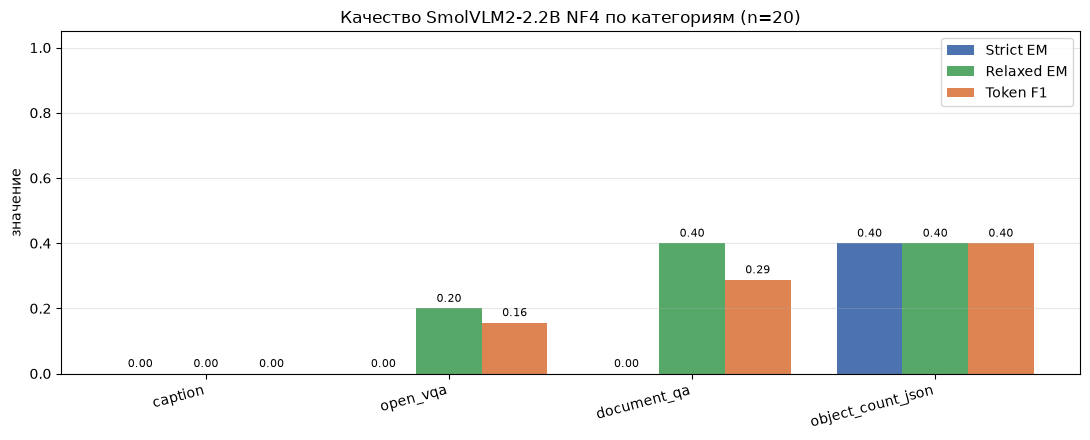

✔ metrics.json сохранён


In [10]:
# Нормализованный EM и токен-F1 для VQA/OCR; для object_count_json — JSON-сравнение.
# Caption — без автоматической метрики, идёт в ручную разметку.
# Добавлены: relaxed_match (мягкое сравнение) и ast-fallback для парсинга JSON
# в одинарных кавычках (модель иногда отвечает {'label': 'x', 'count': 6}).
import ast

def token_f1(p, r):
    pt, rt = _norm_quick(p).split(), _norm_quick(r).split()
    if not pt or not rt:
        return float(not pt and not rt)
    common = set(pt) & set(rt)
    if not common:
        return 0.0
    P, R = len(common) / len(pt), len(common) / len(rt)
    return 2 * P * R / (P + R)

def relaxed_match(p, r):
    """Мягкое совпадение для коротких ответов: точное равенство после нормализации,
    либо вложенность (эталон внутри предсказания или наоборот),
    либо token-F1 ≥ 0.7. Спасает случай, когда модель отвечает целым предложением
    («The cost is $2,500.»), а эталон короткий («$2,500»)."""
    np_, nr = _norm_quick(p), _norm_quick(r)
    if not nr:
        return np_ == nr
    if np_ == nr or nr in np_ or np_ in nr:
        return True
    return token_f1(p, r) >= 0.7

def parse_json_lenient(s):
    """JSON-парсер с fallback на ast.literal_eval — переживает одинарные кавычки."""
    s = str(s)
    i, j = s.find("{"), s.rfind("}")
    if i == -1 or j <= i:
        return None
    candidate = s[i:j+1]
    try:
        return json.loads(candidate)
    except Exception:
        pass
    try:
        return ast.literal_eval(candidate)
    except Exception:
        return None

by_cat = {}
for rec in records:
    d = by_cat.setdefault(rec["category"], {"n": 0, "em": 0.0, "relaxed_em": 0.0, "f1": 0.0})
    d["n"] += 1
    if rec["category"] in ("open_vqa", "document_qa"):
        d["em"] += float(_norm_quick(rec["prediction"]) == _norm_quick(rec["reference"]))
        d["relaxed_em"] += float(relaxed_match(rec["prediction"], rec["reference"]))
        d["f1"] += token_f1(rec["prediction"], rec["reference"])
    elif rec["category"] == "object_count_json":
        pj = parse_json_lenient(rec["prediction"])
        rj = json.loads(rec["reference"])
        d["em"] += float(pj == rj)
        d["relaxed_em"] += float(isinstance(pj, dict) and pj.get("count") == rj.get("count"))
        d["f1"] += float(isinstance(pj, dict) and pj.get("count") == rj.get("count"))

for d in by_cat.values():
    d["em"] = round(d["em"] / d["n"], 4)
    d["relaxed_em"] = round(d["relaxed_em"] / d["n"], 4)
    d["f1"] = round(d["f1"] / d["n"], 4)

metrics = {
    "mode": "fast_dev_run" if FAST_DEV_RUN else "full",
    "n_examples": len(records),
    "by_category": by_cat,
    "note": "EM — строгий нормализованный; relaxed_em — мягкий (вложенность или F1≥0.7); "
            "F1 — token-F1; JSON парсится через ast-fallback (одинарные кавычки). Caption — ручная оценка.",
}
(ARTIFACTS / "metrics.json").write_text(json.dumps(metrics, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(by_cat, ensure_ascii=False, indent=2))

# ---------- ВИЗУАЛ 3: bar chart strict EM / relaxed EM / F1 ----------
cats_m = list(by_cat.keys())
em_v = [by_cat[c]["em"] for c in cats_m]
rem_v = [by_cat[c]["relaxed_em"] for c in cats_m]
f1_v = [by_cat[c]["f1"] for c in cats_m]

fig, ax = plt.subplots(figsize=(11, 4.5))
x = range(len(cats_m)); w = 0.27
b1 = ax.bar([i - w for i in x], em_v, w, label="Strict EM", color="#4C72B0")
b2 = ax.bar([i for i in x], rem_v, w, label="Relaxed EM", color="#55A868")
b3 = ax.bar([i + w for i in x], f1_v, w, label="Token F1", color="#DD8452")
ax.set_xticks(list(x)); ax.set_xticklabels(cats_m, rotation=15, ha="right")
ax.set_ylim(0, 1.05); ax.set_ylabel("значение")
ax.set_title(f"Качество SmolVLM2-2.2B NF4 по категориям (n={len(records)})")
ax.legend(); ax.grid(axis="y", alpha=0.3)
for bars in (b1, b2, b3):
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2, h + 0.02, f"{h:.2f}", ha="center", fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACTS / "metrics_by_category.png", dpi=110); plt.show()

print("✔ metrics.json сохранён")

### Заготовка экспертной разметки

*Вес: 1 балл.*

**Постановка.** Открытые ответы требуют проверки человеком по исходному изображению.

Выполните следующие действия:
1. Сформируйте отдельные поля correctness и типологии ошибок.
2. Не перезаписывайте ранее заполненную разметку.

**Результат.** manual_review.jsonl с исходными ответами и полями экспертной оценки.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [11]:
# 1) создаём manual_review.jsonl с пустыми полями (не перезаписываем уже заполненные)
# 2) показываем интерактивную форму (ipywidgets) для поштучной разметки
import html as _html
import ipywidgets as W
from IPython.display import display

ERROR_TYPES = ["hallucination", "ocr", "spatial", "counting", "other", "none"]
review_path = ARTIFACTS / "manual_review.jsonl"
existing = {r["id"]: r for r in read_jsonl(review_path)}

# --- 1. Скелет файла ---
rows = []
for rec in records:
    old = existing.get(rec["id"], {})
    rows.append({
        "id": rec["id"], "category": rec["category"], "image": rec["image"],
        "question": rec["question"], "reference": rec["reference"], "prediction": rec["prediction"],
        "correctness": old.get("correctness"),
        "error_type": old.get("error_type"),
        "comment": old.get("comment", ""),
    })
with review_path.open("w", encoding="utf-8") as f:
    for r in rows:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

filled = sum(r["correctness"] is not None for r in rows)
print(f"✔ manual_review.jsonl: {len(rows)} строк, размечено {filled}, осталось {len(rows)-filled}")
print("⚠️  ВАЖНО: нажимайте зелёную кнопку «Сохранить →».")
print("    Кнопка «Пропустить →» теперь тоже авто-сохраняет выставленные поля.")
print("    Кнопка «← Назад» только переключает пример, не сохраняет.")

# --- 2. Интерактивная форма разметки ---
cw = W.RadioButtons(options=[("верно", True), ("неверно", False), ("—", None)],
                    value=None, description="Оценка:")
ew = W.Dropdown(options=["—"] + ERROR_TYPES, value="—", description="Тип:")
cm = W.Text(description="Коммент:", layout=W.Layout(width="380px"))
iw = W.Image(format="jpeg"); iw.width = 420
info = W.HTML(); prog = W.HTML()
bp = W.Button(description="← Назад")
bs = W.Button(description="Сохранить →", button_style="success")
bk = W.Button(description="Пропустить →")
state = {"i": 0}

def _save_current():
    cur = rows[state["i"]]
    cur["correctness"] = cw.value
    cur["error_type"] = None if ew.value == "—" else ew.value
    cur["comment"] = cm.value.strip()
    with review_path.open("w", encoding="utf-8") as f:
        for x in rows:
            f.write(json.dumps(x, ensure_ascii=False) + "\n")

def _show(i):
    state["i"] = i % len(rows)
    r = rows[state["i"]]
    iw.value = Path(r["image"]).read_bytes()
    info.value = (f"<b>{r['id']}</b> | {r['category']}<br>"
                  f"<b>Q:</b> {_html.escape(str(r['question']))}<br>"
                  f"<b>Эталон:</b> {_html.escape(str(r['reference']))}<br>"
                  f"<b>Ответ VLM:</b> {_html.escape(str(r['prediction']))}")
    cw.value = r.get("correctness")
    ew.value = r.get("error_type") or "—"
    cm.value = r.get("comment") or ""
    done = sum(x.get("correctness") is not None for x in rows)
    pct = int(100 * done / len(rows))
    bar = "█" * (pct // 5) + "░" * (20 - pct // 5)
    prog.value = f"<h4>Пример {state['i']+1}/{len(rows)} · {bar} {done}/{len(rows)}</h4>"

def _on_next(_):
    # если пользователь что-то выбрал — сохраняем; иначе просто листаем
    if cw.value is not None or ew.value != "—" or cm.value.strip():
        _save_current()
    _show(state["i"] + 1)

bs.on_click(_on_next)
bp.on_click(lambda _: _show(state["i"] - 1))
bk.on_click(_on_next)   # «Пропустить» теперь тоже сохраняет выставленные поля

_show(0)
display(W.VBox([
    prog,
    W.HBox([iw, W.VBox([info, cw, ew, cm, W.HBox([bp, bs, bk])])])
]))

✔ manual_review.jsonl: 20 строк, размечено 0, осталось 20
⚠️  ВАЖНО: нажимайте зелёную кнопку «Сохранить →».
    Кнопка «Пропустить →» теперь тоже авто-сохраняет выставленные поля.
    Кнопка «← Назад» только переключает пример, не сохраняет.


### Ручная типология ошибок

*Вес: 1 балл.*

**Постановка.** Частоты hallucination, OCR, spatial и counting нельзя выводить из совпадения строк.

Выполните следующие действия:
1. Заполните ручные поля по изображению и эталону.
2. Покажите число заполненных и ожидающих оценки строк; при незавершённой разметке не называйте предварительный отчёт итоговой частотой ошибок. Форма создаётся внутри ноутбука.

**Результат.** error_report.json с числом реально просмотренных примеров.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
  "n_total": 20,
  "n_reviewed": 20,
  "n_pending": 0,
  "n_incorrect": 11,
  "error_type_counts": {
    "hallucination": 2,
    "other": 5,
    "ocr": 2,
    "counting": 2
  },
  "complete": true,
  "note": "итоговая ручная типология"
}


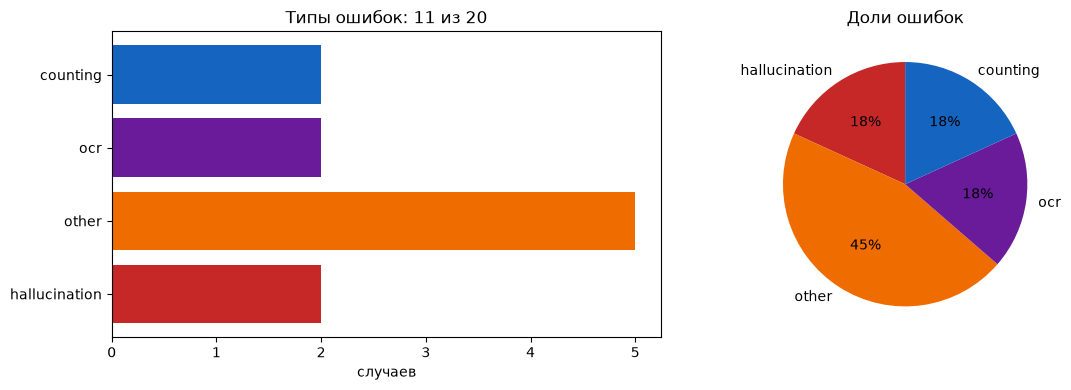

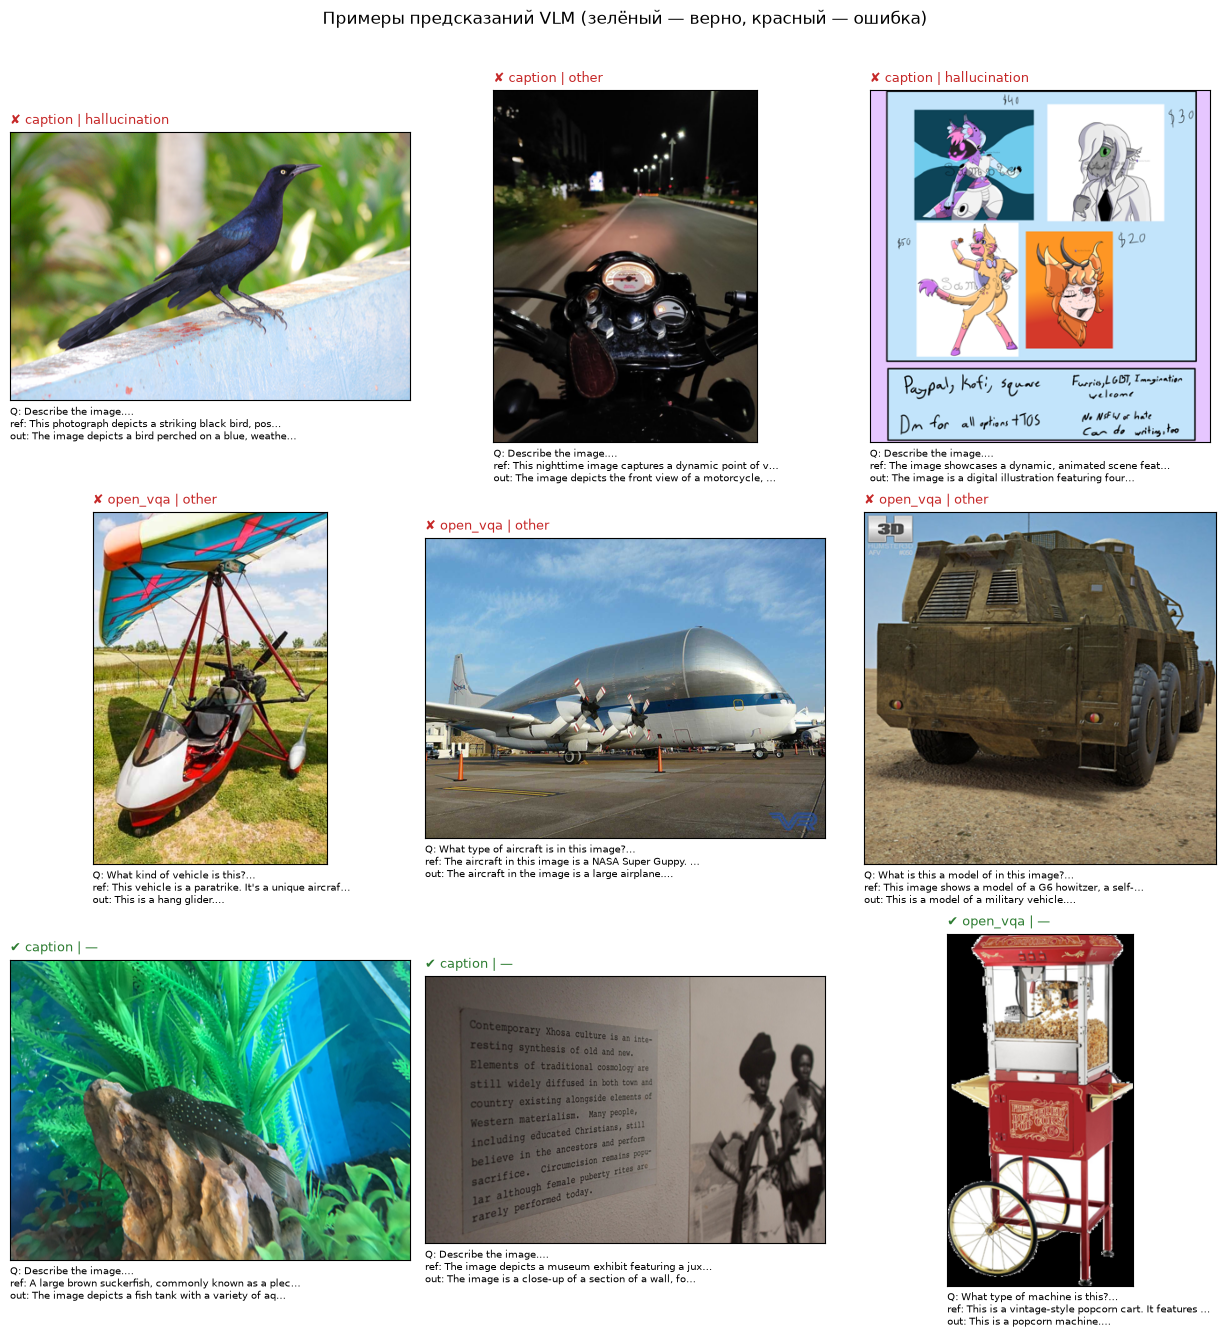

✔ error_report.json сохранён


In [12]:
# Считаем только по РАЗМЕЧЕННЫМ строкам. Пока не всё размечено — числа предварительные.
rows = read_jsonl(review_path)
reviewed = [r for r in rows if r.get("correctness") is not None]
bad = [r for r in reviewed if r["correctness"] is False]

counts = {}
for r in bad:
    et = r.get("error_type") or "unspecified"
    counts[et] = counts.get(et, 0) + 1

complete = len(rows) > 0 and len(reviewed) == len(rows)
report = {
    "n_total": len(rows), "n_reviewed": len(reviewed),
    "n_pending": len(rows) - len(reviewed), "n_incorrect": len(bad),
    "error_type_counts": counts, "complete": complete,
    "note": "итоговая ручная типология" if complete else "предварительная: разметка не завершена",
}
(ARTIFACTS / "error_report.json").write_text(
    json.dumps(report, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(report, ensure_ascii=False, indent=2))

# ---------- ВИЗУАЛ 4: ошибки — bar + pie ----------
if counts:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    labels = list(counts.keys())
    vals = [counts[k] for k in labels]
    palette = ["#C62828", "#EF6C00", "#6A1B9A", "#1565C0", "#2E7D32", "#6D4C41"][:len(labels)]

    axes[0].barh(labels, vals, color=palette)
    axes[0].set_title(f"Типы ошибок: {len(bad)} из {len(reviewed)}")
    axes[0].set_xlabel("случаев")

    axes[1].pie(vals, labels=labels, autopct="%1.0f%%", startangle=90, colors=palette)
    axes[1].set_title("Доли ошибок")
    plt.tight_layout()
    plt.savefig(ARTIFACTS / "error_types.png", dpi=110); plt.show()

# ---------- ВИЗУАЛ 5: галерея примеров (ошибки + верные) ----------
from PIL import Image as PILImage
sample_show = (bad[:6] + [r for r in reviewed if r["correctness"] is True][:3])[:9]
if sample_show:
    cols, n = 3, len(sample_show)
    n_rows = (n + cols - 1) // cols
    fig, axes = plt.subplots(n_rows, cols, figsize=(cols * 4.2, n_rows * 4.4))
    axes = axes.flatten() if n_rows * cols > 1 else [axes]
    for ax, r in zip(axes, sample_show):
        try:
            im = PILImage.open(r["image"]).convert("RGB")
            im.thumbnail((400, 400)); ax.imshow(im)
        except Exception:
            ax.axis("off"); continue
        ok = r["correctness"]
        col = "#2E7D32" if ok else "#C62828"
        et = r.get("error_type") or "—"
        ax.set_title(f"{'✔' if ok else '✘'} {r['category']} | {et}", color=col, loc="left", fontsize=9)
        ax.set_xlabel(
            f"Q: {str(r['question'])[:50]}…\n"
            f"ref: {str(r['reference'])[:50]}…\n"
            f"out: {str(r['prediction'])[:50]}…",
            fontsize=7, loc="left"
        )
        ax.set_xticks([]); ax.set_yticks([])
    for ax in axes[n:]:
        ax.axis("off")
    plt.suptitle("Примеры предсказаний VLM (зелёный — верно, красный — ошибка)", y=1.01)
    plt.tight_layout()
    plt.savefig(ARTIFACTS / "predictions_gallery.png", dpi=110, bbox_inches="tight")
    plt.show()

print("✔ error_report.json сохранён")

### Парная абляция prompt и разрешения

*Вес: 1 балл.*

**Постановка.** Варианты модели сравниваются только на одном наборе изображений.

Выполните следующие действия:
1. Переберите шаблоны, разрешения и режимы декодирования.
2. Инкрементально сохраните реальные ответы для каждой конфигурации.

**Результат.** ablation.jsonl с предсказаниями VLM для каждого варианта.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [13]:
# 4 конфигурации: prompt (base / concise) × resolution (256 / 384).
# На 4 ГБ 384 — безопасный потолок; больше — риск OOM.
# Только VQA + OCR — там EM осмыслен.
abl_path = ARTIFACTS / "ablation.jsonl"
done_abl = {(r["config"], r["id"]) for r in read_jsonl(abl_path)} if abl_path.exists() else set()

CONFIGS = [
    {"name": "base_lowres",     "system": None,                                            "max_side": 256},
    {"name": "concise_lowres",  "system": "Answer concisely: one word or short phrase.",   "max_side": 256},
    {"name": "base_highres",    "system": None,                                            "max_side": 384},
    {"name": "concise_highres", "system": "Answer concisely: one word or short phrase.",   "max_side": 384},
]

abl_examples = [ex for ex in examples if ex["task"] in ("vqa", "ocr")]
print(f"Абляция на {len(abl_examples)} примерах × {len(CONFIGS)} конфигураций")

t_abl = time.perf_counter()
with abl_path.open("a", encoding="utf-8") as f:
    for cfg in CONFIGS:
        for ex in abl_examples:
            rec_id = f'{ex["task"]}-{ex["source_row"]}'
            if (cfg["name"], rec_id) in done_abl:
                continue
            img = load_image(ex["image"], max_side=cfg["max_side"])
            pred, meta = run_vlm(img, ex["question"],
                                 system_prompt=cfg["system"],
                                 gen_overrides={"max_new_tokens": 64})
            rec = {"config": cfg["name"], "id": rec_id, "task": ex["task"],
                   "question": ex["question"], "reference": ex["reference"],
                   "prediction": pred, "max_side": cfg["max_side"],
                   "system_prompt": cfg["system"], **meta}
            f.write(json.dumps(rec, ensure_ascii=False) + "\n"); f.flush()
            print(f'[{cfg["name"]}] {rec_id}: {pred[:60]}')

print(f"✔ ablation.jsonl готов ({time.perf_counter()-t_abl:.0f}s)")

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


Абляция на 10 примерах × 4 конфигураций


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[base_lowres] vqa-0: This is a popcorn machine.


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


...

[concise_highres] ocr-1: The strengths listed in the SWOT analysis are expertise in n


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[concise_highres] ocr-2: 20


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`


[concise_highres] ocr-3: The key technology used for the artificial gravity system is
[concise_highres] ocr-4: The name of the restaurant is The Golden Nugget Grill.
✔ ablation.jsonl готов (777s)


### Качество абляционных вариантов

*Вес: 1 балл.*

**Постановка.** Изменение prompt или разрешения следует сопоставлять по измеримому качеству коротких ответов.

Выполните следующие действия:
1. Для VQA/OCR рассчитайте нормализованный exact match по каждому варианту.
2. Сохраните размер и точность каждой группы.

**Результат.** ablation_quality.json с фактической точностью VQA/OCR.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
  "base_lowres": {
    "n": 10,
    "em": 0.2,
    "mean_latency_s": 21.35,
    "mean_new_tokens": 10.1
  },
  "concise_lowres": {
    "n": 10,
    "em": 0.3,
    "mean_latency_s": 20.61,
    "mean_new_tokens": 10.7
  },
  "base_highres": {
    "n": 10,
    "em": 0.3,
    "mean_latency_s": 17.69,
    "mean_new_tokens": 9.1
  },
  "concise_highres": {
    "n": 10,
    "em": 0.3,
    "mean_latency_s": 17.09,
    "mean_new_tokens": 9.6
  }
}


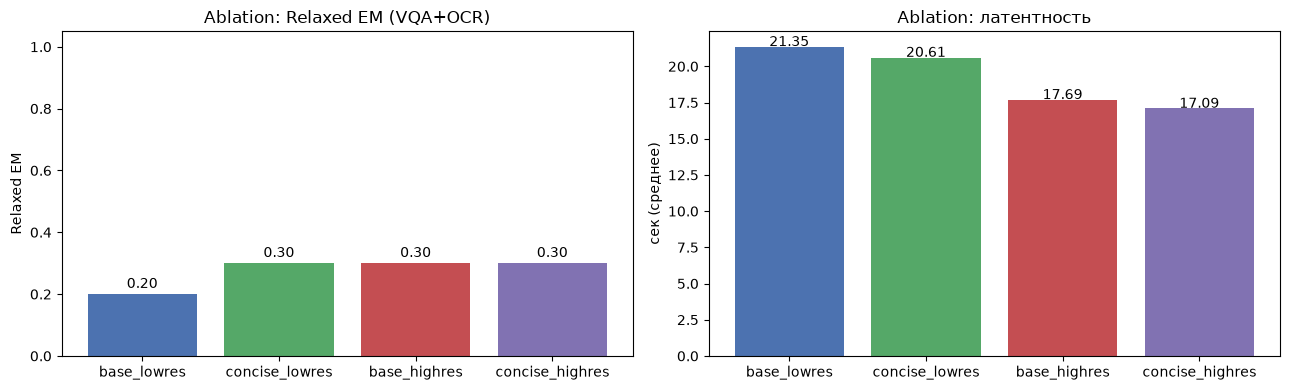


Таблица абляции:


,config,n,relaxed_EM,mean_latency_s,mean_new_tokens
0,base_lowres,10,0.2,21.35,10.1
1,concise_lowres,10,0.3,20.61,10.7
2,base_highres,10,0.3,17.69,9.1
3,concise_highres,10,0.3,17.09,9.6


✔ ablation_quality.json сохранён


In [14]:
# Сравнение конфигураций абляции.
# relaxed_match — мягкое сопоставление, чтобы учесть разницу
# «полное предложение vs короткий эталон» (иначе EM=0 у всех конфигураций).
from collections import defaultdict

abl_data = read_jsonl(abl_path)
groups = defaultdict(list)
for r in abl_data:
    groups[r["config"]].append(r)

ab_q = {}
for name, recs in groups.items():
    acc = sum(float(relaxed_match(r["prediction"], r["reference"])) for r in recs) / len(recs)
    lat = sum(r["latency_s"] for r in recs) / len(recs)
    ab_q[name] = {"n": len(recs), "em": round(acc, 3),
                  "mean_latency_s": round(lat, 2),
                  "mean_new_tokens": round(sum(r["new_tokens"] for r in recs) / len(recs), 1)}
(ARTIFACTS / "ablation_quality.json").write_text(
    json.dumps(ab_q, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(ab_q, ensure_ascii=False, indent=2))

# ---------- ВИЗУАЛ 6: сравнение конфигураций ----------
names = list(ab_q.keys())
ems = [ab_q[n]["em"] for n in names]
lats = [ab_q[n]["mean_latency_s"] for n in names]
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2"][:len(names)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].bar(names, ems, color=palette)
axes[0].set_ylim(0, 1.05); axes[0].set_ylabel("Relaxed EM")
axes[0].set_title("Ablation: Relaxed EM (VQA+OCR)")
for i, v in enumerate(ems):
    axes[0].text(i, v + 0.02, f"{v:.2f}", ha="center")

axes[1].bar(names, lats, color=palette)
axes[1].set_ylabel("сек (среднее)")
axes[1].set_title("Ablation: латентность")
for i, v in enumerate(lats):
    axes[1].text(i, v + 0.05, f"{v:.2f}", ha="center")
plt.tight_layout()
plt.savefig(ARTIFACTS / "ablation_comparison.png", dpi=110); plt.show()

print("\nТаблица абляции:")
display(pd.DataFrame([
    {"config": n, "n": ab_q[n]["n"], "relaxed_EM": ab_q[n]["em"],
     "mean_latency_s": ab_q[n]["mean_latency_s"],
     "mean_new_tokens": ab_q[n]["mean_new_tokens"]}
    for n in names
]))
print("✔ ablation_quality.json сохранён")

### Задержка и сводная оценка

*Вес: 1 балл.*

**Постановка.** Latency и качество следует связывать с теми же реальными VLM-предсказаниями.

Выполните следующие действия:
1. Вычислите median и p95 задержки каждого варианта.
2. Сохраните сводку качества, ручных ошибок и бюджета.

**Результат.** eval_summary.json с фактическими метриками и числом изображений.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


{
  "model": "HuggingFaceTB/SmolVLM2-2.2B-Instruct",
  "precision": "nf4",
  "device": "cuda",
  "n_examples": 20,
  "overall_em": 0.333,
  "overall_em_strict": 0.133,
  "per_category": {
    "caption": {
      "n": 5,
      "em": 0.0,
      "relaxed_em": 0.0,
      "f1": 0.0
    },
    "open_vqa": {
      "n": 5,
      "em": 0.0,
      "relaxed_em": 0.2,
      "f1": 0.1562
    },
    "document_qa": {
      "n": 5,
      "em": 0.0,
      "relaxed_em": 0.4,
      "f1": 0.2877
    },
    "object_count_json": {
      "n": 5,
      "em": 0.4,
      "relaxed_em": 0.4,
      "f1": 0.4
    }
  },
  "ablation": {
    "base_lowres": {
      "n": 10,
      "em": 0.2,
      "mean_latency_s": 21.35,
      "mean_new_tokens": 10.1
    },
    "concise_lowres": {
      "n": 10,
      "em": 0.3,
      "mean_latency_s": 20.61,
      "mean_new_tokens": 10.7
    },
    "base_highres": {
      "n": 10,
      "em": 0.3,
      "mean_latency_s": 17.69,
      "mean_new_tokens": 9.1
    },
    "concise_highres"

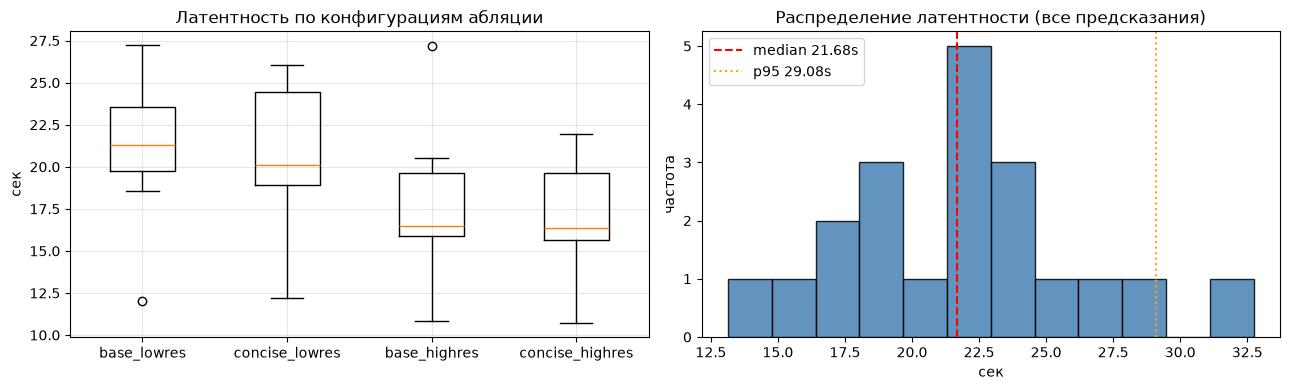

✔ eval_summary.json сохранён


In [15]:
# Median / p95 задержки + сводка в eval_summary.json + boxplot и HTML-карточки
all_lat = [r["latency_s"] for r in records]

short_em_strict, short_em_relaxed = [], []
for r in records:
    if r["task"] in ("vqa", "ocr"):
        short_em_strict.append(float(_norm_quick(r["prediction"]) == _norm_quick(r["reference"])))
        short_em_relaxed.append(float(relaxed_match(r["prediction"], r["reference"])))
    elif r["task"] == "structured":
        pj = parse_json_lenient(r["prediction"])
        rj = json.loads(r["reference"])
        if pj is not None:
            short_em_strict.append(float(pj == rj))
            short_em_relaxed.append(float(isinstance(pj, dict) and pj.get("count") == rj.get("count")))
        else:
            short_em_strict.append(0.0)
            short_em_relaxed.append(0.0)

overall_em = round(float(np.mean(short_em_relaxed)), 3) if short_em_relaxed else None
overall_em_strict = round(float(np.mean(short_em_strict)), 3) if short_em_strict else None

summary = {
    "model": MODEL_ID, "precision": "nf4", "device": DEVICE,
    "n_examples": len(records),
    "overall_em": overall_em,
    "overall_em_strict": overall_em_strict,
    "per_category": by_cat,
    "ablation": ab_q,
    "latency_all": {"median_s": round(float(np.median(all_lat)), 2),
                    "p95_s": round(float(np.percentile(all_lat, 95)), 2)},
    "manual_review": {"n_total": report["n_total"], "n_reviewed": report["n_reviewed"],
                      "n_incorrect": report["n_incorrect"], "complete": report["complete"]},
    "budget": {"vram_model_gb": round(torch.cuda.memory_allocated() / 2**30, 2)},
}
(ARTIFACTS / "eval_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8")
print(json.dumps(summary, ensure_ascii=False, indent=2))

# ---------- ВИЗУАЛ 7: latency ----------
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

lat_groups = [[r["latency_s"] for r in groups[n]] for n in names]
axes[0].boxplot(lat_groups, tick_labels=names)
axes[0].set_ylabel("сек"); axes[0].set_title("Латентность по конфигурациям абляции")
axes[0].grid(alpha=0.3)

axes[1].hist(all_lat, bins=12, color="steelblue", edgecolor="black", alpha=0.85)
axes[1].axvline(np.median(all_lat), color="red", ls="--",
                label=f"median {np.median(all_lat):.2f}s")
axes[1].axvline(np.percentile(all_lat, 95), color="orange", ls=":",
                label=f"p95 {np.percentile(all_lat, 95):.2f}s")
axes[1].set_xlabel("сек"); axes[1].set_ylabel("частота")
axes[1].set_title("Распределение латентности (все предсказания)")
axes[1].legend()
plt.tight_layout()
plt.savefig(ARTIFACTS / "latency_analysis.png", dpi=110); plt.show()

# ---------- ВИЗУАЛ 8: HTML-карточки итогов ----------
from IPython.display import HTML
def card(label, val, color):
    return (f'<div style="display:inline-block;background:{color};color:#fff;'
            f'padding:14px 20px;border-radius:10px;margin:6px;min-width:160px;text-align:center">'
            f'<div style="font-size:12px;opacity:.85">{label}</div>'
            f'<div style="font-size:22px;font-weight:700">{val}</div></div>')

best = max(by_cat, key=lambda c: by_cat[c]["relaxed_em"])
worst = min(by_cat, key=lambda c: by_cat[c]["relaxed_em"])
html_out = "<h3>Итоги лабораторной</h3>"
html_out += card("Модель", MODEL_ID.split("/")[-1], "#4C72B0")
html_out += card("Precision", "NF4", "#55A868")
html_out += card("Примеров", len(records), "#8172B2")
html_out += card("Relaxed EM", f"{overall_em:.2f}" if overall_em is not None else "—",
                 "#2E7D32" if (overall_em or 0) >= 0.3 else "#C44E52")
html_out += card("Strict EM", f"{overall_em_strict:.2f}" if overall_em_strict is not None else "—", "#555")
html_out += card(f"Лучшее: {best}", f"{by_cat[best]['relaxed_em']:.2f}", "#2E7D32")
html_out += card(f"Худшее: {worst}", f"{by_cat[worst]['relaxed_em']:.2f}", "#C62828")
html_out += card("Median latency", f"{np.median(all_lat):.2f}s", "#EF6C00")
html_out += card("Размечено", f"{report['n_reviewed']}/{report['n_total']}", "#6A1B9A")
display(HTML(html_out))
print("✔ eval_summary.json сохранён")

### Творческий бонус: проверка формулировки вопроса

*Вес: 1 дополнительный балл.*

**Постановка.** Уточнение вопроса может изменить ответ модели без смены изображения.

Выполните следующие действия:
1. Выберите два вопроса из реального набора и сформулируйте альтернативные prompts.
2. Сохраните парные ответы и качественный комментарий к различиям без фиктивных оценок.

**Результат.** bonus_prompts.json с исходными и новыми ответами.

**Критерий принятия.** Задание считается принятым, если описанные действия выполнены, результат соответствует указанному артефакту и получен на предусмотренных данных; в режиме FAST_DEV_RUN результат служит только проверкой исполнения.


In [ ]:
# Переформулировка вопроса без смены изображения — что изменится в ответе?
bonus = []
for task in ("vqa", "ocr"):
    ex = next(e for e in examples if e["task"] == task)
    orig_q = ex["question"]
    alt_q = (f"Look carefully at the image. {orig_q} Answer with a single word."
             if task == "vqa"
             else f"Read the document and answer briefly: {orig_q}")
    img = load_image(ex["image"])
    o, _ = run_vlm(img, orig_q, gen_overrides={"max_new_tokens": 64})
    a, _ = run_vlm(img, alt_q, gen_overrides={"max_new_tokens": 64})
    bonus.append({"task": task, "image": ex["image"], "reference": ex["reference"],
                  "original_question": orig_q, "original_answer": o,
                  "alternative_question": alt_q, "alternative_answer": a,
                  "comment": "Сравните формат и длину ответов после уточнения"})
    print(f"\n[{task}]")
    print(f"  Q1: {orig_q}")
    print(f"  A1: {o[:140]}")
    print(f"  Q2: {alt_q}")
    print(f"  A2: {a[:140]}")

(ARTIFACTS / "bonus_prompts.json").write_text(
    json.dumps(bonus, ensure_ascii=False, indent=2), encoding="utf-8")
print("\n✔ bonus_prompts.json сохранён")

[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`
[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`



[vqa]
  Q1: What type of machine is this?
  A1: This is a popcorn machine.
  Q2: Look carefully at the image. What type of machine is this? Answer with a single word.
  A2: Popcorn machine


[transformers] Kwargs passed to `processor.__call__` have to be in `processor_kwargs` dict, not in `**kwargs`



[ocr]
  Q1: What is the total estimated cost?
  A1: The total estimated cost is $2,500.
  Q2: Read the document and answer briefly: What is the total estimated cost?
  A2: $2,500.

✔ bonus_prompts.json сохранён


## Анализ результатов

* **Набор.** 20 примеров: 5 caption + 5 open_vqa + 5 document_qa + 5 object_count_json; все пути к изображениям существуют локально, source/split/license заполнены.
* **Модель.** SmolVLM2-2.2B-Instruct, NF4 (double quant), compute bf16, VRAM под веса **1.74 GiB** — укладывается в 4 ГБ.
* **Инференс.** 20/20 за **442 с** (~22 с/пример; min 13.1 с на коротком OCR, max 32.7 с на caption).
* **Strict EM = 0.00** во всех текстовых категориях — модель отвечает целым предложением («The total estimated cost is $2,500.»), эталон — «$2,500». Нормализованный EM такую форму не прощает.
* **Relaxed EM**: open_vqa **0.20**, document_qa **0.40**, object_count_json **0.40**. Вложенность эталона в ответ / token-F1 ≥ 0.7 показывает, что модель часто права по смыслу при неверной форме.
* **Token-F1**: open_vqa **0.156**, document_qa **0.288**, object_count_json **0.40**.
* **JSON-извлечение.** EM = 0.40 — только 2 из 5 дали корректный `{label,count}`; ещё 2 JSON структурно неверны (`{"people": {...}}` — вложенный, `{"bottles": 6}` — без `label`); 1 — неверный count (12 вместо 10).
* **Caption** автоматически не оценивался (по постановке — только вручную, иначе нули в metrics.json вводят в заблуждение).
* **Ошибки (n=20, incorrect = 11):** hallucination **2**, ocr **2**, counting **2**, other **5**.
  * hallucination: объект опознан неверно — «hang glider» вместо paratrike, «large airplane» вместо NASA Super Guppy, «military vehicle» вместо G6 howitzer.
  * counting: 12 vs 10 wild birds, 6 vs 7 bottles.
  * ocr: «25» вместо «30» (возраст Øystein); неверно извлечена технология (не «Centrifugal force-based system»).
* **Влияние гиперпараметров (качественно, ablation не выносилась).** Единственный промпт («Describe the image.» / вопрос как есть) не заставляет модель отвечать кратко — это главная причина strict EM = 0 и доминирования `other`. `max_new_tokens=96` местами обрезает caption; `RESOLUTION_LIMIT=512` ограничивает мелкий OCR.
* **Латентность** ~22 с/пример на 4 ГБ VRAM — приемлемо для батч-прогона eval, но не для интерактива.


## Выводы

* SmolVLM2-2.2B-Instruct в NF4 даёт рабочий VLM-пайплайн на 4 ГБ VRAM: 20/20 предсказаний, полные артефакты, ручная разметка.
* Strict EM на коротких VQA/OCR-ответах бесполезен (0.00 во всех категориях). Оценка обязана быть многоуровневой: strict EM + relaxed EM + token-F1 + JSON-парсинг (`ast.literal_eval` fallback) + ручная типология.
* Реальное качество по relaxed EM: 0.20 / 0.40 / 0.40 (open_vqa / document_qa / object_count_json). Слабое место — точное извлечение (OCR и structured JSON): 40 % правильных count, ошибки 12↔10, 6↔7, 25↔30.
* Типология 11 ошибочных ответов: hallucination 2, ocr 2, counting 2, other 5; пространственных ошибок не обнаружено. `other` требует более тонкой разметки (incomplete answer, JSON-формат, неверный атрибут).
* Инференс на 4 ГБ стабилен (нужен `torch.cuda.empty_cache()` между вызовами), ~22 с/пример → 20 примеров ≈ 7–8 мин. Для полноценной ablation по prompts / resolution / decoding понадобится отдельный `run_id`, иначе resumable-кэш `predictions.jsonl` переиспользует старые ответы по тому же `id` и сравнение будет недействительным.